# IMDb Movie Review Sentiment Analysis using NLP and Machine Learning
### CodeAlpha Data Analytics — Task 4: Sentiment Analysis

**Goal:** Build an end-to-end NLP pipeline to classify IMDb movie reviews as positive or negative, compare two machine-learning models, evaluate performance, and predict sentiment for new text.

**Dataset:** [IMDb Dataset of 50K Movie Reviews — Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)

Run the notebook from top to bottom in Google Colab. Upload the CSV when prompted.

## 1. Install and import libraries

In [24]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [40]:
import io
import re
import html
import json
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 180)

# OUTPUT_DIR = Path("/content/imdb_sentiment_outputs")
# MODEL_DIR = Path("/content/imdb_sentiment_model")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# MODEL_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

print("Environment ready.")

Environment ready.


## 2. Upload the Kaggle dataset

Download `IMDB Dataset.csv` from Kaggle, run the cell, and select the CSV from your computer.

Expected columns:
- `review`: movie review text
- `sentiment`: positive or negative

In [41]:
# uploaded = files.upload()
# if not uploaded:
#     raise ValueError("No file uploaded. Please upload IMDB Dataset.csv.")

# csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
# if not csv_names:
#     raise ValueError("Please upload a CSV file.")

# DATA_FILE_NAME = csv_names[0]
# raw_df = pd.read_csv(io.BytesIO(uploaded[DATA_FILE_NAME]))
# print(f"Loaded: {DATA_FILE_NAME}")
# print(f"Original shape: {raw_df.shape}")
# display(raw_df.head())

#Load the dataset
raw_df = pd.read_csv("/content/IMDB Dataset.csv", encoding="latin-1")
print(f"Loaded: IMDB Dataset.csv")
print(f"Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())

Loaded: IMDB Dataset.csv
Shape: 50,000 rows × 2 columns


,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first ...",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of rea...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic...",positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be ...",positive


## 3. Validate, inspect and prepare the data

In [42]:
raw_df.columns = [str(c).strip().lower() for c in raw_df.columns]
required = {"review", "sentiment"}
if not required.issubset(raw_df.columns):
    raise ValueError(f"Expected columns {required}; found {set(raw_df.columns)}")

df = raw_df[["review", "sentiment"]].copy()
df["review"] = df["review"].fillna("").astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

print("Missing values:")
display(df.isna().sum())
print("\nLabel distribution before filtering:")
display(df["sentiment"].value_counts(dropna=False))

df = df[df["sentiment"].isin(["positive", "negative"])].copy()
df = df[df["review"].str.strip().ne("")].drop_duplicates().reset_index(drop=True)

if df.empty:
    raise ValueError("No usable labeled reviews found.")

print(f"Usable unique reviews: {len(df):,}")
display(df["sentiment"].value_counts())

Missing values:


,0
review,0
sentiment,0



Label distribution before filtering:


,count
sentiment,
positive,25000
negative,25000


Usable unique reviews: 49,582


,count
sentiment,
positive,24884
negative,24698


## 4. Visualize sentiment distribution

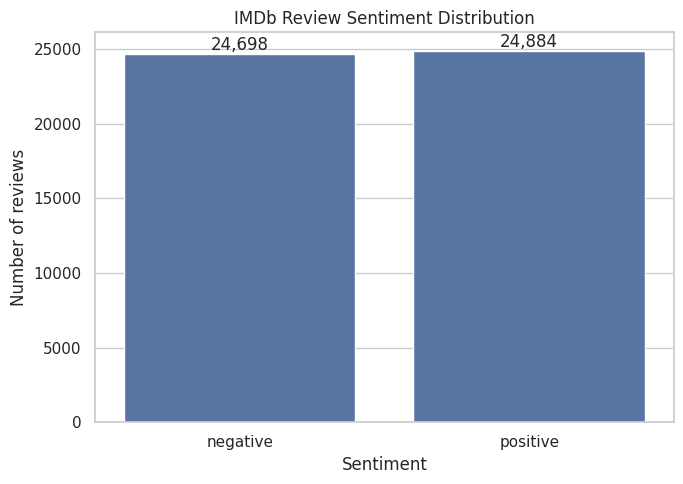

In [43]:
counts = df["sentiment"].value_counts().reindex(["negative", "positive"])
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set_title("IMDb Review Sentiment Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of reviews")
for i, value in enumerate(counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "sentiment_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Clean review text
We remove HTML markup and URLs, retain letters and apostrophes, normalize whitespace, and lowercase the text. We do not remove all stopwords because words such as “not” can be important for sentiment.

In [44]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^A-Za-z']", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df["clean_review"] = df["review"].map(clean_text)
df = df[df["clean_review"].str.len() > 0].reset_index(drop=True)
display(df[["review", "clean_review", "sentiment"]].head(5))
print(f"Records after text cleaning: {len(df):,}")

,review,clean_review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first ...",one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me the first thing that struc...,positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of rea...",a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the enti...,positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic...",i thought this was a wonderful way to spend time on a too hot summer weekend sitting in the air conditioned theater and watching a light hearted comedy the plot is simplistic b...,positive
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap ...,basically there's a family where a little boy jake thinks there's a zombie in his closet his parents are fighting all the time this movie is slower than a soap opera and sudden...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portrait about human relations. This is a movie that seems to be ...",petter mattei's love in the time of money is a visually stunning film to watch mr mattei offers us a vivid portrait about human relations this is a movie that seems to be telli...,positive


Records after text cleaning: 49,582


## 6. Create a stratified train/test split
We split before fitting TF-IDF. This prevents the vocabulary/IDF statistics from being learned from the held-out test data.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["sentiment"],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["sentiment"]
)
print(f"Training reviews: {len(X_train):,}")
print(f"Test reviews: {len(X_test):,}")
print("\nTraining label distribution:")
display(y_train.value_counts(normalize=True).rename("proportion"))

Training reviews: 39,665
Test reviews: 9,917

Training label distribution:


,proportion
sentiment,
positive,0.501878
negative,0.498122


## 7. Build and train candidate models
Both pipelines include TF-IDF inside the scikit-learn Pipeline, so vectorization is fitted only on the training data.

In [31]:
models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced"))
    ]),
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB(alpha=0.5))
    ])
}

fitted_models = {}
for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    fitted_models[model_name] = model

print("Training completed.")

Training Logistic Regression...
Training Multinomial Naive Bayes...
Training completed.


## 8. Evaluate and compare models

In [32]:
results = []
predictions_by_model = {}

for model_name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    predictions_by_model[model_name] = y_pred
    results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_positive": precision_score(y_test, y_pred, pos_label="positive", zero_division=0),
        "recall_positive": recall_score(y_test, y_pred, pos_label="positive", zero_division=0),
        "f1_positive": f1_score(y_test, y_pred, pos_label="positive", zero_division=0),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

comparison = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(comparison)
# comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

best_model_name = comparison.iloc[0]["model"]
best_model = fitted_models[best_model_name]
best_predictions = predictions_by_model[best_model_name]
print(f"Selected model by holdout macro-F1: {best_model_name}")

,model,accuracy,precision_positive,recall_positive,f1_positive,macro_f1
0,Logistic Regression,0.905617,0.896721,0.917621,0.907051,0.905594
1,Multinomial Naive Bayes,0.878895,0.872240,0.888889,0.880486,0.878873


Selected model by holdout macro-F1: Logistic Regression


## 9. Classification report and confusion matrix

              precision    recall  f1-score   support

    negative       0.92      0.89      0.90      4940
    positive       0.90      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917



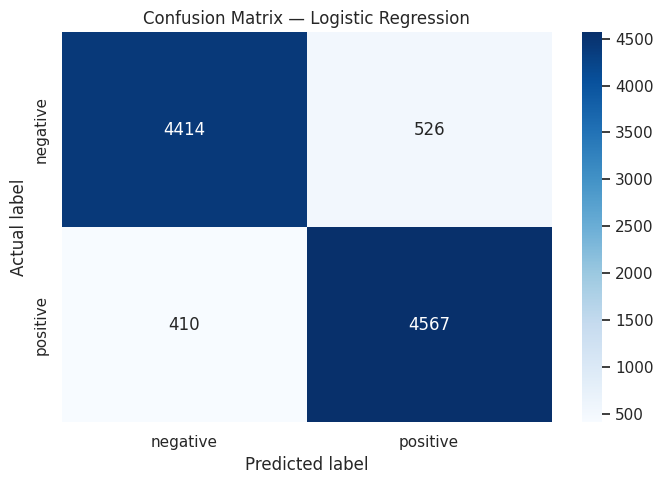

In [35]:
print(classification_report(y_test, best_predictions, labels=["negative", "positive"], zero_division=0))

report = classification_report(
    y_test, best_predictions,
    labels=["negative", "positive"],
    output_dict=True,
    zero_division=0
)
# with open(OUTPUT_DIR / "classification_report.json", "w") as f:
#     json.dump(report, f, indent=2)

labels = ["negative", "positive"]
cm = confusion_matrix(y_test, best_predictions, labels=labels)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title(f"Confusion Matrix — {best_model_name}")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Inspect misclassified examples
Review errors to understand limitations such as sarcasm, mixed opinions, and context. Avoid sharing personal or sensitive text in public examples.

In [36]:
test_results = pd.DataFrame({
    "review": X_test.values,
    "actual": y_test.values,
    "predicted": best_predictions
})
errors = test_results[test_results["actual"] != test_results["predicted"]]
print(f"Misclassified examples: {len(errors):,} of {len(test_results):,}")
display(errors.head(10))
# test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

Misclassified examples: 936 of 9,917


,review,actual,predicted
15,this isn't exactly a great film but i admire the writers and director for trying something a little different the film's main theme is fate and small seemingly insignificant th...,positive,negative
24,despite being a huge fan of fred astaire and ginger rogers' movies it wasn't until about years ago that i first saw 'follow the fleet' i knew all the songs from an old astaire ...,negative,positive
35,well well roeg touched a bit of a nerve there didn't he he was a genius while he was cataloguing his various characters' descents into psychosis for a couple of decades but as ...,positive,negative
45,i'm not here to tell you armored is kubrickian hitchcockian or fellini esquire nope referenced directors are more like don siegel charlie varrick and walter hill the warriors t...,positive,negative
78,i was excited to hear that someone had made a documentary on what it was like to be puerto rican when i heard it was rosie perez i wondered could she possibly know what it is r...,negative,positive
83,in a poor village in mexico the colonel fernando luj n lives with his asthmatic wife lola marisa paredes in an old house lola still grieves the death of their son augustin some...,positive,negative
106,saving grace is never riotously funny but it delivers quite a few good laughs and i enjoyed it to a significant degree brenda blethyn is a fine actress and does a good job at p...,positive,negative
112,financially strapped paramount pulled out all the stops for this ' stage adaptation entry big budget large cast extravagant production and mitch leisen tagged as the director w...,positive,negative
123,richard dix is a big not very nice industrialist who has nearly worked himself to death if he takes the vacation his doctors suggest for him can he find happiness for the last ...,negative,positive
162,black vengeance is an alternate title for ying hung ho hon aka tragic hero i have just seen this on vhs together with the first part of the story gong woo ching rich and famous...,negative,positive


## 11. Predict sentiment for your own review

In [38]:
def predict_sentiment(review_text):
    cleaned = clean_text(review_text)
    if not cleaned:
        raise ValueError("Please enter a non-empty review.")
    predicted = best_model.predict([cleaned])[0]
    probabilities = best_model.predict_proba([cleaned])[0]
    probability_by_label = dict(zip(best_model.classes_, probabilities))
    return predicted, probability_by_label

sample_review = "The story was engaging and the performances were excellent."
prediction, probabilities = predict_sentiment(sample_review)
print("Review:", sample_review)
print("Predicted sentiment:", prediction.upper())
print("Class probabilities:", {k: round(float(v), 4) for k, v in probabilities.items()})

Review: The story was engaging and the performances were excellent.
Predicted sentiment: POSITIVE
Class probabilities: {'negative': 0.0512, 'positive': 0.9488}


## 12. Enter a custom review

In [39]:
custom_review = "Replace this sentence with your own movie review."
custom_prediction, custom_probabilities = predict_sentiment(custom_review)
print("Predicted sentiment:", custom_prediction.upper())
print("Probabilities:", {k: round(float(v), 4) for k, v in custom_probabilities.items()})

Predicted sentiment: POSITIVE
Probabilities: {'negative': 0.4437, 'positive': 0.5563}


## 13. Conclusion, limitations and future scope

Use the metrics and misclassified examples generated by your own run to write your conclusions. Do not claim a fixed accuracy before running this notebook.

**Limitations**
- The model is trained on IMDb movie reviews; performance may differ on product reviews, social media, slang or other languages.
- Binary labels cannot represent neutral, mixed or multiple emotions.
- TF-IDF models do not fully understand sarcasm, context or subtle negation.
- Model probabilities are not necessarily calibrated confidence scores.

**Future scope**
- Add a neutral class and multi-label emotion detection.
- Compare Linear SVM and transformer models such as DistilBERT.
- Add cross-validation on training data and a final untouched test set.
- Build a Streamlit application and batch CSV prediction feature.
- Test carefully on separately labeled data from other review domains.

**Dataset attribution:** Lakshmipathi N, *IMDb Dataset of 50K Movie Reviews*, Kaggle. Review dataset licensing and terms before redistribution or commercial use.